# Parameter fitting

## Introduction

Abby, E., Dentro, S.C., Hall, M.W.J. et al. Notch1 mutations drive clonal expansion in normal esophageal epithelium but impair tumor growth. Nat Genet 55, 232–245 (2023). https://doi.org/10.1038/s41588-022-01280-z

Vasiliki Kostiou, Huairen Zhang, Michael W. J. Hall, Philip H. Jones, Benjamin A. Hall; Methods for analysing lineage tracing datasets. R. Soc. Open Sci. 1 May 2021; 8 (5): 202231. https://doi.org/10.1098/rsos.202231

https://github.com/PHJonesGroup/Abby_etal_SI_code

In this part of the tutorial we will take a model representing an experiment and attempt to find a set of parameters that best describe a dataset. We are working from clonal data published in Abby et al, 2023 specifically an experimental model of NOTCH1 single and double mutations. In this case parameter fitting was used to show NOTCH1 loss of function mutations are haploinsufficient. That is to say, that loss of one allele leads to a phenotype. We are further able to argue that the loss of the second allele shows an epistatic effect- the increase in fitness is greater than would be expected if mutations acted independently. The implications of these effects are discussed in the lectures and later in this document.

We are trying to infer two model parameters in a simple model in this practical that reflect unmeasured features from the original *lineage tracing* experiment. In the experiment, a small fraction of mutations with an inheritable label are induced in a small fraction of cells at an initial timepoint. At a later time, the mouse is sacrificed and labelled cells counted using a microscope. We can imagine the two model parameters as

1) Induction rate- what fraction of mutant cells have mutations induced in the experiment
2) Fitness- what the relative advantage of mutant cells is over unmutated cells (whose fitness is set to 1)

The experiment measures surviving clone sizes at different time points. Clones are induced at a low level to minimise the chance of collision, and we therefore assume that contiguous labelled clones have a single cell of origin. These clone sizes are used to find parameters.

## Key learning points

In this notebook you will be doing more coding, simulation, and plotting. In working through this notebook you should learn how a variety of different functions can be run. In terms of coding, writing basic functions and specifically using matplotlib

* Making scatter plots from datasets
* Making heatmaps
* Making line graphs, and overlaying raw data/uncertainty onto those graphs

In terms of conceptual learning, you should be comfortable comparing different statistical methods 

## Strategy

In the original work, *approximate Bayesian computation* (ABC) was used to infer parameters. Experience in working with mouse data had previously shown that this gave a realistic estimate of uncertainty due to the small number of replicates common to the field compared to maximum likelihood techniques (Kostiou et al, 2021). The code used in Abby et al is included with this practical (/clonal_dynamics_simulations) for your information. ABC is however a computationally intensive technique and not practical in this lab setting. We therefore use a simulation based maximum likelihood approach to identify adequeate parameters and then compare our models back to the original data.

*This approach has known weaknesses that will become clear in the outputs of the practical! Be aware that it's imperfect and compare the results you find to the stored plots from Abby!*

We wish to perform a comparison between simulations of a parameter set and experimental observations, and return something comparable to a probability. Here what we have chosen to compare the mean clone size at different experimental times with simulation as this is a straightfoward metric to interpret that potentially carries sufficient information. To turn this comparison into a log likelihood, we follow this approach

1) simulate a number of clones over all timepoints
2) extract the surviving clone sizes at experimental timepoints
3) use *bootstrapping with replacement* to generate a distribution of mean clone sizes from the simulated clone sizes at each timepoint
4) fit a Gaussian distribution to these observed distributions, and from this fitted distribution, calculated the log likelihood for each timepoint
5) sum the log-likelihoods across all timepoints and return this value

This ultimately gives a pipeline where

(induction, fitness) -> simulation -> synthetic log likelihood

We use this pipeline to search different parameters in a grid and identify the most probable sets of parameters, and the shape of the probability surface. From this surface we can also try calculate the parameter ranges that include 95% of all possible values (effectively a 95% confidence interval).

*Question- how does bootstrapping work? Why is it useful here?*

Our search strategy is two steps based around a grid search of different parameters. We define a range of parameters in which we perform a coarse grain search, before using the result to perform a more fine grain search around the best results.

## Before starting

Examine "FittingResults" in /clonal_dynamics_simulations to check the published results. 

*Do not rerun! It doesn't contain the generated data and all the figures will disappear*

This code can be rerun with a Moran process instead of a Wright-Fisher model. This functionality is available for you to explore but increases the time required by one to two orders of magnitude and searches will not complete in the practical session.

## "Boilerplate" code and setting global variables

First we import key libraries, create some functions to silence the simulator and therefore allow us to run it repeatedly easily, and set some global parameters. 

New libraries that are important to the approach here are *multivariate_normal*, which is used to calculate the likelihood of a pair of simulations and experimental observations, and *joblib*, which allows us to run our simulations over multiple cores in your computer.

In [1]:
import numpy as np
import pandas as pd
from collections import OrderedDict
from scipy.stats import multivariate_normal
from scipy.stats import sem
import matplotlib.pyplot as plt

from joblib import Parallel, delayed

from clone_competition_simulation.parameters import Parameters, TimeParameters, PopulationParameters, LabelParameters, FitnessParameters

In [2]:
# Silence the progress bar — must use the module reference directly
import clone_competition_simulation.simulation_algorithms.simulation_loop as sl
from rich.console import Console
sl.console = Console(quiet=True)

#and in joblib
def _silence_progress():
    import clone_competition_simulation.simulation_algorithms.simulation_loop as sl
    from rich.console import Console
    from loguru import logger
    
    sl.console = Console(quiet=True)
    logger.disable("clone_competition_simulation")

The global parameters define a mixture of important but uninsightul variables (e.g. the location of the dataset) and key simulation and inference parameters.

For all our simulations we use a model with 250000 cells, of which 100 are needed to survive as mutant clones at everytime point. The division rate is defined from experiments.

We set an *ERROR_OBJECT*- an object that is returned if a simulation fails. The format given here is the same format that our functions return- a dictionary with a single key, distance. In our code the distance is a synthetic log likelihood, so the error obect is set to negative infinity to mark it as a parameter that is never good.

Finally we specify 
*LOOP_LIMITS* - how many times can a simulation fail before we move on
*SIMS_PER_PARAMETER* - defining how many simulations are run to estimate the log-likelihood
*N_BOOTSTRAP* - how many bootstrap replicates are used based on the simulations (explained later)

In [3]:
DATA_FILE = "data/09-03-21 Final clonal counting dataset.xlsx"

# Functions and fixed parameters for simulations
GRID_SHAPE = (500, 500)
DIVISION_RATE = 0.27
CELLS = GRID_SHAPE[0]*GRID_SHAPE[1]

ERROR_OBJECT = {'distance': -np.inf}
NUM_CLONES = 100

LOOP_LIMITS = 10
SIMS_PER_PARAMETER = 100
N_BOOTSTRAP = 1000

## Common functions

Next we define functions (taken from the previous implmentation) that perform fundamental tasks. First we have a series of functions that extract basal cell counts from the spreadsheet. This is important but essentially hardcoded parameters taht specifiy which cells to look in for different data sets. These are given unique keys to allow the user to specify which dataset they want- "hom" and "het" contain clonal data from double and single NOTCH1 knockout mutations respectively, whilst "wt", "het_ctl", and "hom_ctl" are all controls expected to be neutral.

We define a function *load_data* that returns an array of experimental times and clone size distributions, and *mean_data* and loads the data and returns an array of experimental times and mean surviving clone sizes.

*Question- why do we refer to surviving clone sizes and not clone sizes?*

In [4]:
def _read_basal_counts(df):
    return OrderedDict([(t, _read_basal_counts_column(df[t])) for t in df.columns])

def _read_basal_counts_column(col):
    return np.array([v for v in col.values if (not np.isnan(v) and v > 0)], dtype=int)
    
def load_data(target_data, data_file):
    target_data = target_data.lower()
    if target_data == 'wt':
        cols = "C,E,G,I,K"
        times = [10, 14, 28, 63, 91]
    elif target_data == 'het':
        cols = "M,O,Q,S"
        times = [10, 28, 63, 91]
    elif target_data == 'het_ctl':
        cols = "U,W,Y,AA"
        times = [10, 28, 63, 91]
    elif target_data == 'hom':
        cols = "AC,AE,AG"
        times = [10, 14, 28]
    elif target_data == 'hom_ctl':
        cols = "AI,AK,AM"
        times = [10, 14, 28]
        
    df = pd.read_excel(data_file, sheet_name="Splitted data table", skiprows=8, 
                       usecols=cols, header=None, names=times, engine='openpyxl')
    return _read_basal_counts(df)

def mean_data(target_data, data_file):
    data = load_data(target_data, data_file)
    mean_dict = OrderedDict()
    for time in data.keys():
        mean_dict[time]=np.mean(data[time])
    return mean_dict

## Simulation initiation

We examine how well different pairs of fitness and induction values describe the data. We therefore define a subroutine that takes a single value for each and information about the simulation size (shape of the grid and number of cells) to produce objects that can be passed to the Parameters object and create a simulator.

In [5]:
def get_grid(fitness, induction, grid_shape, cells):
    # Make the initial grid with randomly placed induced cells
    initial_grid = np.zeros(grid_shape, dtype=int)
    total_mutants = int(induction*cells)
    mutant_locs = np.random.choice(grid_shape[0]*grid_shape[1], total_mutants, replace=False)
    mutant_locs = [(m // grid_shape[1], m % grid_shape[1]) for m in mutant_locs]  # Convert the random draws into array indices

    count = 0
    for i in range(total_mutants):
        initial_grid[mutant_locs[count]] = i + 1
        count += 1

    fitness_array = [1] + [fitness]*total_mutants
    label_array = [0] + [1]*total_mutants
    return initial_grid, fitness_array, label_array

*Task- load, explore, and plot the experimental results* 

In [6]:
test = load_data('wt', DATA_FILE)

In [7]:
tmean = mean_data('wt', DATA_FILE)
print(tmean)

OrderedDict({10: np.float64(3.194871794871795), 14: np.float64(3.1456953642384105), 28: np.float64(6.042553191489362), 63: np.float64(6.076923076923077), 91: np.float64(10.182539682539682)})


## Parameter fitting function

The *get_sim_mean_pl* function does the key work of parameter fitting- it takes parameters (as a dictionary) and experimental data and returns a synthetic log likelihood. The code below can be understood as follows

1) Set up a parameters object using induction and fitness parameters, as well as hardcoded global parameters.
2) Run simulations repeatedly (up to a maximum defined by LOOP_LIMITS) until we have simulated enough clones at every timepoint to analyse (defined by NUM_CLONES). Store the clone sizes at different timepoints.
3) Use a bootstrap approach to calculate N_BOOTSTRAP alternative means from each timepoint.
4) From an array of N_BOOTSTRAP means, find the mean value of the logs of the means, and the covariance matrix for the logs of the means (effectively fitting a Gaussian distribution to the logged values)
5) Use multivariate_normal.logpdf to calculate the log likelihood of the (logged) mean observed clone sizes at each timepoint when compared to the fitted Gaussian distribution
6) Return this log likelihood

If anything goes wrong, return ERROR_OBJECT

*Task- go through the code below and annotate it with comments based on the scheme above. Run individual lines and look up function definitions to confirm and reinforce your understanding*


In [8]:
def get_sim_mean_pl(parameters, target_data, algorithm='WF2D'):
    fitness, induction = parameters['fitness'], parameters['induction']
    times = [t for t in target_data]
    try:
        initial_grid, fitness_array, label_array = get_grid(fitness, induction, GRID_SHAPE, CELLS)
        if len(fitness_array) == 1:  # Induction rate too low. No mutants on grid.
            return ERROR_OBJECT
            
        p = Parameters(algorithm=algorithm, 
                       population=PopulationParameters(initial_grid=initial_grid,cell_in_own_neighbourhood=True),
                       times=TimeParameters(times=times, division_rate=DIVISION_RATE), 
                       labels=LabelParameters(initial_label_array=label_array),
                       fitness=FitnessParameters(initial_fitness_array=fitness_array)
                       )
        clone_counts = np.zeros(len(times), dtype=int)
        
        sim_distributions = [[] for i in range(len(times))]
        if p:
            for loop in range(LOOP_LIMITS):
                s = p.get_simulator()
                s.run_sim()
                for i, t in enumerate(times):
                    clone_sizes = s.get_clone_sizes_array_for_non_mutation(t=t, index_given=False, exclude_zeros=True,
                                                                       label=1)
                    clone_counts[i] += len(clone_sizes)
                    sim_distributions[i].extend(clone_sizes)

                if np.all(clone_counts >= NUM_CLONES):
                    # Have got enough clones
                    break

            if not np.all(clone_counts >= NUM_CLONES):
                # Reached loop limit before getting required number of clones.
                return ERROR_OBJECT

            sim_means = np.zeros((N_BOOTSTRAP, len(times)))
            
            for b in range(N_BOOTSTRAP):
                for i, t in enumerate(times):
                    resample = np.random.choice(sim_distributions[i], size=NUM_CLONES, replace=True)
                    sim_means[b, i] = np.mean(resample)

            mean_vec = np.mean(np.log(sim_means), axis=0)      # shape (len(times),)
            cov_mat  = np.cov(np.log(sim_means), rowvar=False)  # shape (len(times), len(times))

            observations = np.array([target_data[t] for t in times])
            
            total_distance = multivariate_normal.logpdf(np.log(observations), mean=mean_vec, cov=cov_mat)
            
            return {'distance': total_distance}
        else:
            return ERROR_OBJECT
    except (Exception, SystemExit) as e:
        print('Error')
        print(e)
        return ERROR_OBJECT

*Task- run some single simulations and examine the outcomes*

In [9]:
test_p = {'fitness':1.5,'induction':0.05}
target_data = mean_data('hom', DATA_FILE)
get_sim_mean_pl(test_p, target_data)

12:58:07 | DEBUG | Times rounded to match simulation steps:  Times used: [11.11111111 14.81481481 29.62962963]


Output()

{'distance': np.float64(-1684.727083948011)}

## Performing a parameter sweep

We now have functions that allow us to take an induction level and a fitness parameter, perform simulations, and compare it to experiments. To find the best parameters we will search alternative parameter combinations in a systematic method. We do this by defining ranges in which we will search and how many parameters we will look at between the ranges.

*pseudoLikelihoodSweep* takes experimental data, ranges, and the number of steps and calculates the log likelihoods for parameters within the range. We could use a for loop, which would run each parameter combination in turn. To speed this up however, we instead use the Parallel object to run it across multiple processors in your computer.

In [10]:
def rangeModifier(valueRange,steps):
    low, high = valueRange
    gradient = (high-low)/steps
    intercept = low+gradient/2
    return(intercept,gradient)

def pseudoLikelihoodSweep(target_data, n=10,fitnessRange=(0,10),inductionRange=(0.005,0.105),algorithm="WF2D"):
    #values = [[0 for i in range(n)] for j in range(n)]
    #result = np.zeros((n,n))
    fi, fg = rangeModifier(fitnessRange,n)
    ii, ig = rangeModifier(inductionRange,n)

    grid = [(i, j, fg*i+fi, ig*j+ii) for i in range(n) for j in range(n)]

    def _worker(i, j, fit, ind):
        p = {'fitness': fit, 'induction': ind}
        r = get_sim_mean_pl(p, target_data,algorithm=algorithm)
        if r == ERROR_OBJECT:
            return i, j, np.nan
        return i, j, r['distance']  # already a log-likelihood, don't log again

    results = Parallel(n_jobs=-1, initializer=_silence_progress)(delayed(_worker)(i, j, fit, ind) for i, j, fit, ind in grid)

    result = np.zeros((n, n))
    values = [[None]*n for _ in range(n)]
    for i, j, val in results:
        result[i][j] = val
        values[i][j] = (fg*i+fi, ig*j+ii)
    
    return(result,values)

In [11]:
fitnessRange=(0,20)
inductionRange=(-0.005,0.095)
steps = 20

In [12]:
params = {'fitness': 7.0, 'induction': 0.002}
result_one = get_sim_mean_pl(params, target_data, )
print(result_one)

12:58:11 | DEBUG | Times rounded to match simulation steps:  Times used: [11.11111111 14.81481481 29.62962963]


Output()

{'distance': np.float64(-247.62511121392615)}


In [13]:
result, values = pseudoLikelihoodSweep(target_data,fitnessRange=fitnessRange,inductionRange=inductionRange,n=steps)

## Plotting the results and finding confidence intervals

We now have a 2D array of log likelihoods representing different parameter combinations. We want to

1) Visualise this array to find the shape of the distribution
2) Find the range of each variable that represent 95% confidence intervals
3) Compare the best fitted parameters with experimental data

The last point is of primary importance; the search should find the *best* parameters; they do not guarantee that the fit is adequate and without issues. If you don't check the results you risk misleading yourself.

Below we define a series of functions that do the key analyses and apply them to the "hom" data.

*Compare the distribution to the ABC results. What are the notable differences and similarities? What aspects of the analysis do you trust and which do you not?*

In [14]:
def fmt(x, sf=2):
    return f"{x:.{sf}g}"

def likelihood_heatmap(data,fitnessRange,inductionRange,steps=10,expTransform=False):
    #if plotting likelihood, convert from log 
    if expTransform:
        data = np.exp(data- np.nanmax(data))
        data = np.where(np.isnan(data), 0, data)
        data /= data.sum()
    
    fig, ax = plt.subplots()
    im = ax.imshow((data), cmap='plasma')
    
    fi, fg = rangeModifier(fitnessRange,steps)
    ii, ig = rangeModifier(inductionRange,steps)
    
    #float(i)+0.5,'induction':float(1+j)/100
    ax.set_xticks(range(steps), [fmt(ig*float(i)+ii) for i in range(steps)])
    ax.set_yticks(range(steps), [fmt(fg*float(i)+fi) for i in range(steps)])

    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
    
    cbar = fig.colorbar(im, ax=ax)
    
    plt.show()

In [15]:
def get_95ci(data,fitnessRange,inductionRange,steps,):
    def credible_interval(vals, probs, ci=0.95):
        """Central credible interval from a discrete 1D distribution."""
        cdf   = np.cumsum(probs)
        lower = vals[np.searchsorted(cdf, (1 - ci) / 2)]
        upper = vals[np.searchsorted(cdf, (1 + ci) / 2)]
        return lower, upper
    
    data = np.exp(data- np.nanmax(data))
    data = np.where(np.isnan(data), 0, data)
    data /= data.sum()
    
    fi, fg = rangeModifier(fitnessRange,steps)
    ii, ig = rangeModifier(inductionRange,steps)
    
    x_vals = [(ig*float(i)+ii) for i in range(steps)]
    y_vals = [(fg*float(i)+fi) for i in range(steps)]
    
    marginal_x = data.sum(axis=0)   # sum over rows → distribution over x
    marginal_y = data.sum(axis=1)   # sum over cols → distribution over y
    
    x_lo, x_hi = credible_interval(x_vals, marginal_x)
    y_lo, y_hi = credible_interval(y_vals, marginal_y)
    
    print(f"x 95% CI: [{x_lo:.2f}, {x_hi:.2f}]")
    print(f"y 95% CI: [{y_lo:.2f}, {y_hi:.2f}]")

    #bounds is a dict of tuples with a new inductionRange 
    bounds = {"inductionRange":(x_lo-ig,x_hi+ig),"fitnessRange":(y_lo-fg,y_hi+fg)}
    
    return({"data":data,
            "x":{"low":x_lo,"high":x_hi},
            "y":{"low":y_lo,"high":y_hi},
            "bounds":bounds,
            "x_vals":x_vals,
            "y_vals":y_vals,
            "marginal_x":marginal_x,
            "marginal_y":marginal_y})

In [16]:
def plot_marginals(ci_result):
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    
    x_vals = np.array(ci_result["x_vals"])
    y_vals = np.array(ci_result["y_vals"])

    marginal_x = ci_result["marginal_x"]
    marginal_y = ci_result["marginal_y"]

    x_lo = ci_result["x"]["low"]
    x_hi = ci_result["x"]["high"]
    y_lo = ci_result["y"]["low"]
    y_hi = ci_result["y"]["high"]
    
    # heatmap
    axes[0].imshow(ci_result["data"], origin='lower', extent=[min(x_vals), max(x_vals), min(y_vals), max(y_vals)], cmap='inferno', aspect='auto')
    axes[0].axvline(x_lo, color='w', linestyle='--', label='x CI')
    axes[0].axvline(x_hi, color='w', linestyle='--')
    axes[0].axhline(y_lo, color='c', linestyle='--', label='y CI')
    axes[0].axhline(y_hi, color='c', linestyle='--')
    axes[0].set_title('Joint distribution')
    axes[0].legend(fontsize=8)
    
    # marginal x
    axes[1].plot(x_vals, marginal_x)
    axes[1].axvline(x_lo, color='r', linestyle='--', label=f'95% CI')
    axes[1].axvline(x_hi, color='r', linestyle='--')
    axes[1].set_title('Marginal x')
    axes[1].legend()
    
    # marginal y
    axes[2].plot(y_vals, marginal_y)
    axes[2].axvline(y_lo, color='r', linestyle='--', label='95% CI')
    axes[2].axvline(y_hi, color='r', linestyle='--')
    axes[2].set_title('Marginal y')
    axes[2].legend()
    
    plt.tight_layout()
    plt.show()

In [17]:
def getBestEdges(result,fitnessRange=(0,10),inductionRange=(0.005,0.105),n=10):
    best_x, best_y = np.unravel_index(np.argmax(result), result.shape)
    fi, fg = rangeModifier(fitnessRange,n)
    lowFit = fitnessRange[0]
    lowInd = inductionRange[0]
    ii, ig = rangeModifier(inductionRange,n)
    edgeX = (lowFit+fg*best_x, lowFit+fg*(best_x+1))
    edgeY = (lowInd+ig*best_y, lowInd+ig*(best_y+1))
    print(best_x,best_y)
    return(edgeX,edgeY)

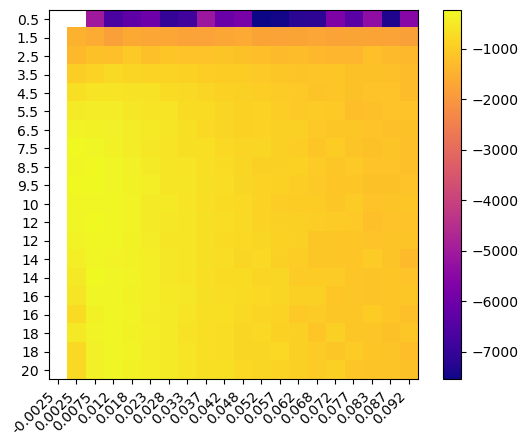

In [18]:
likelihood_heatmap(result,fitnessRange,inductionRange,steps=steps)

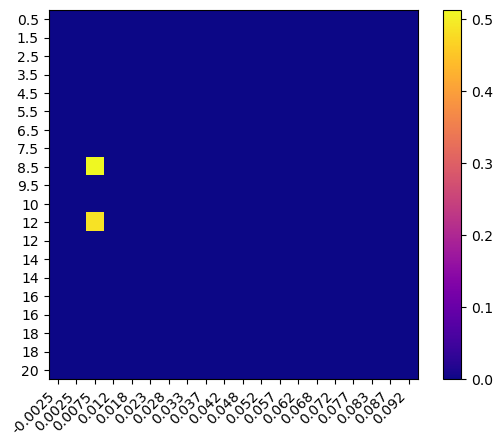

In [19]:
likelihood_heatmap(result,fitnessRange,inductionRange,steps=steps,expTransform=True)

In [20]:
top_coarse_fitness, top_coarse_induction = getBestEdges(result,n=steps)

0 0


In [21]:
data = np.exp(result- np.nanmax(result))
data = np.where(np.isnan(data), 0, data)
data /= data.sum()


'\nprob_surface = np.exp(grid - np.nanmax(grid))\nprob_surface = np.where(np.isnan(prob_surface), 0, prob_surface)\nprob_surface /= prob_surface.sum()\n'

In [22]:
ci_hom = get_95ci(result,fitnessRange,inductionRange,steps)

x 95% CI: [0.01, 0.01]
y 95% CI: [8.50, 11.50]


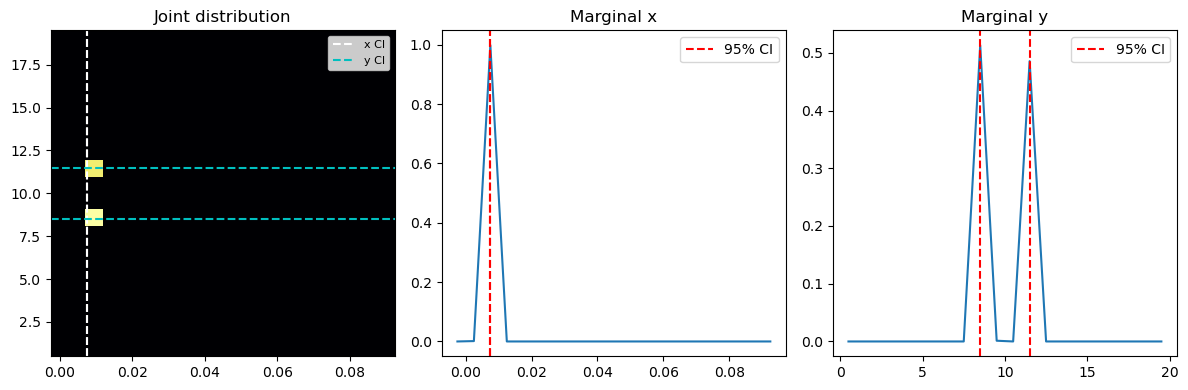

In [23]:
plot_marginals(ci_hom)

Now we have an estimate of the best parameter, we can search in the area of the peak specifically for a more precise estimation of the distribution of values. This is calculated in the function and returned in the dictionary object with the "bounds" key.

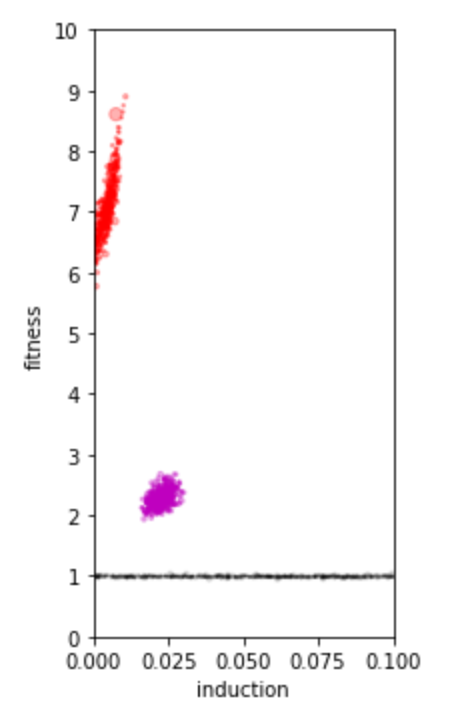

*Question- compare this distribution to the hom data (red) from ABC above. How is it different? Where do you think the differences come from, and how could you improve the outcome?*

In [24]:
result_hom_tight, values_hom_tight = pseudoLikelihoodSweep(target_data,fitnessRange=ci_hom["bounds"]["fitnessRange"],inductionRange=ci_hom["bounds"]["inductionRange"],n=steps)

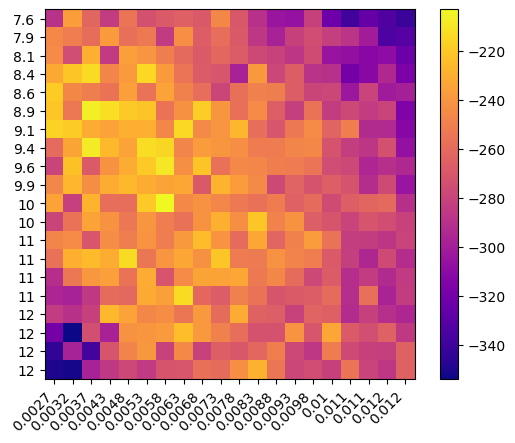

In [25]:
likelihood_heatmap(result_hom_tight,ci_hom["bounds"]["fitnessRange"],ci_hom["bounds"]["inductionRange"],steps=steps)

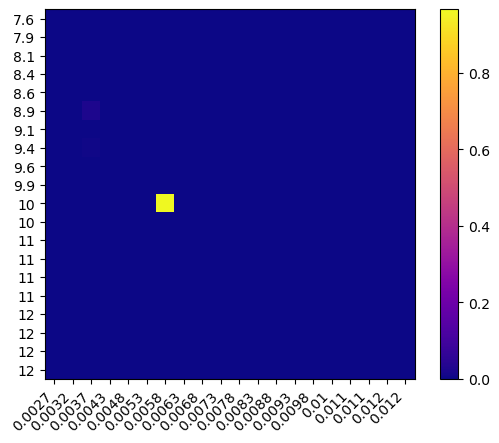

In [26]:
likelihood_heatmap(result_hom_tight,ci_hom["bounds"]["fitnessRange"],ci_hom["bounds"]["inductionRange"],steps=steps,expTransform=True)

In [27]:
ci_hom_tight = get_95ci(result_hom_tight,ci_hom["bounds"]["fitnessRange"],ci_hom["bounds"]["inductionRange"],steps)

x 95% CI: [0.00, 0.01]
y 95% CI: [8.88, 10.12]


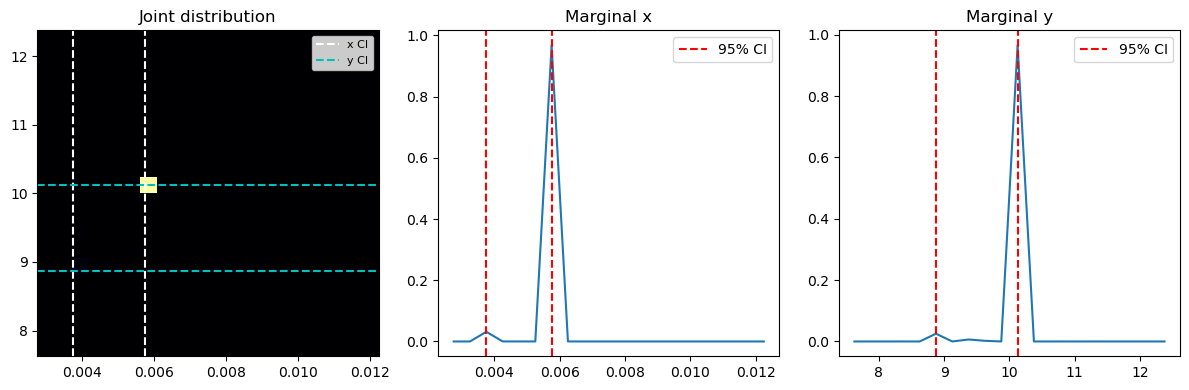

In [28]:
plot_marginals(ci_hom_tight)

*Why do we not see a smooth distribution of values? How might we fix this?*

## Compare with the data (do the best fits fit?)

Having found a single parameter we need to compare this to experimental data to explore the quality of fit. To do this we take our  parameters (defined as the midpoint in our confidence interval), run a series of new simulations and compare the means with the experimental distributions.

In [29]:
def run_sim(parameters, target_data, return_clone_sizes=False, algorithm="WF2D"):
    fitness, induction = parameters['fitness'], parameters['induction']
    times = [t for t in target_data]

    try:
        initial_grid, fitness_array, label_array = get_grid(fitness, induction, GRID_SHAPE, CELLS)
        if len(fitness_array) == 1:  # Induction rate too low. No mutants on grid.
            return ERROR_OBJECT

        p = Parameters(algorithm=algorithm, 
               population=PopulationParameters(initial_grid=initial_grid,cell_in_own_neighbourhood=True),
               times=TimeParameters(times=times, division_rate=DIVISION_RATE), 
               labels=LabelParameters(initial_label_array=label_array),
               fitness=FitnessParameters(initial_fitness_array=fitness_array)
               )
        
        clone_counts = np.zeros(len(times), dtype=int)
        sim_distributions = [[] for i in range(len(times))]
        if p:
            for loop in range(LOOP_LIMITS):
                s = p.get_simulator()
                s.run_sim()
                for i, t in enumerate(times):
                    clone_sizes = s.get_clone_sizes_array_for_non_mutation(t=t, index_given=False, exclude_zeros=True,
                                                                       label=1)
                    clone_counts[i] += len(clone_sizes)
                    sim_distributions[i].extend(clone_sizes)

                if np.all(clone_counts >= NUM_CLONES):
                    # Have got enough clones
                    break

            if not np.all(clone_counts >= NUM_CLONES):
                # Reached loop limit before getting required number of clones.
                return ERROR_OBJECT

            res = OrderedDict([
                (t, np.random.choice(sim_distributions[i], size=NUM_CLONES, replace=False)) for i, t in enumerate(times)
            ])
            if return_clone_sizes:
                return res

            total_distance = sum([distance_ks(target_data[t], res[t]) for t in target_data])
            return {'distance': total_distance}
        else:
            return ERROR_OBJECT
    except (Exception, SystemExit) as e:
        print('Error')
        print(e)
        return ERROR_OBJECT
        

def get_sim_means(parameters, num, data, max_attempts_per_sample=10, algorithm="WF2D"):
    res = [[] for t in data]
    
    i = 0
    attempts = 0
    successes = 0
    while successes < num:
        print(successes, end=' ')
        np.random.seed(i)
        clone_sizes = run_sim(parameters=parameters, target_data=data, return_clone_sizes=True, algorithm=algorithm)
        i += 1
        attempts += 1

        # Detect failure: ERROR_OBJECT won't have one entry per timepoint in `data`
        if clone_sizes is ERROR_OBJECT or set(clone_sizes.keys()) != set(data.keys()):
            if attempts - successes > max_attempts_per_sample * num:
                raise RuntimeError("Too many failed simulations — check parameters.")
            continue

        for j, (t, clones) in enumerate(clone_sizes.items()):
            res[j].append(clones.mean())
        successes += 1

    intervals_high = [1]
    intervals_low = [1]
    means = [1]
    for r in res:
        intervals_high.append(np.quantile(r, 0.975))
        intervals_low.append(np.quantile(r, 0.025))
        means.append(np.mean(r))
    
    return means, intervals_high, intervals_low

def plot_data(results, colour=None, label=None, err_stat=sem, elinewidth=2, capsize=4, markersize=3):
    x = results.keys()
    y = [results[k].mean() for k in results]
    yerr = [err_stat(results[k]) for k in results]
    plt.errorbar(x, y, yerr=yerr, label=label, c=colour, 
                 elinewidth=elinewidth, 
                 capsize=capsize, capthick=elinewidth,
                 markersize=markersize,
                 fmt='o')

def ci_to_params(ci_result):
    #returns the value half way between CIs

    #use bounds as names are unambigous
    bounds = ci_result['bounds']
    
    fit = np.mean(bounds["fitnessRange"])
    ind = np.mean(bounds["inductionRange"])
    return {'fitness': fit, 'induction': ind}

In [30]:
HOM = load_data('hom', DATA_FILE)
HOM_PARAMS = ci_to_params(ci_hom_tight)
hom_means, hom_interval_high, hom_interval_low = get_sim_means(HOM_PARAMS, 100, HOM)

0 

13:09:14 | DEBUG | Times rounded to match simulation steps:  Times used: [11.11111111 14.81481481 29.62962963]


Output()

13:09:15 | DEBUG | Times rounded to match simulation steps:  Times used: [11.11111111 14.81481481 29.62962963]


1 

Output()

... (286 outputs left out)

Output()

13:10:15 | DEBUG | Times rounded to match simulation steps:  Times used: [11.11111111 14.81481481 29.62962963]


99 

Output()

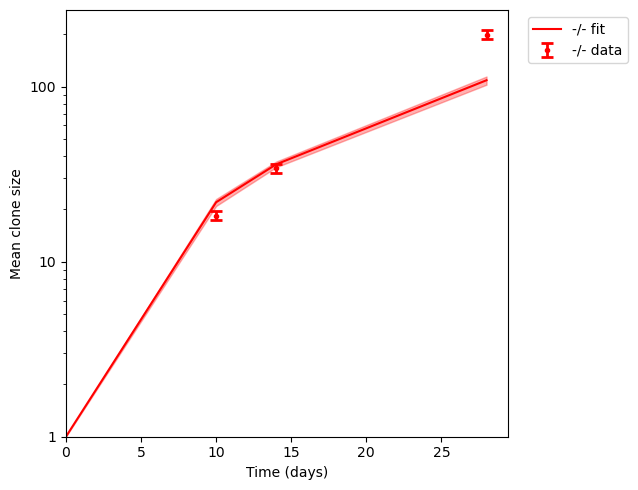

In [31]:
plt.figure(figsize=(6.5, 5))


data = HOM
colour_sim = 'r'
colour_data = 'r'
times = [0] + [t for t in data]
plt.plot(times, hom_means, label='-/- fit', c=colour_sim)
plt.fill_between(times, hom_interval_high, hom_interval_low, alpha=0.3, color=colour_sim)
plot_data(data, label='-/- data', colour=colour_data)


plt.xlim(left=0)
plt.legend(bbox_to_anchor=(1.03, 1))
plt.yscale('log')
plt.ylabel('Mean clone size')
plt.xlabel('Time (days)')
plt.ylim(bottom=1)
plt.yticks([1, 10, 100], [1, 10, 100]);
plt.tight_layout()

## Questions

1) Analyse plots from the "hom" dataset. How well does the data fit? 
2) How does the fitting plot change if you manually select alternative (worse) parameters?
3) Does the apparent uncertainty from the parameter sweep (95% confidence intervals) reflect the change in apparent fit? Add to the plotting functions an estimate of r^2 to quantify the fit of different parameters

## Tasks

Repeat the "hom" analysis on other datasets and present the results

What is different about the uncertainty of control datasets? Why do you think this is?

In [32]:
# YOUR CODE HERE 
raise NotImplementedError